# IaCGen - error categories against IaCGen-MAS (CloudFormation, DeepSeek-V4-Flash)

In [1]:
import sys, os, re, json, csv, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore")
sys.path.insert(0, "audit")
import repair_loop as rl
import error_categories as ec
csv.field_size_limit(sys.maxsize)
FINAL = Path("../results"); RUNS = "../runs"; DATA = Path("../data"); RES = Path("result/final")
IG_DIR = Path("../results/CFN_RealAWS_IaCGen_DSV4Flash")
CACHE = FINAL / "_analysis_cache"
plt.style.use("ggplot"); sns.set_palette("muted")
pd.set_option("display.width", 230, "display.max_columns", 40, "display.max_colwidth", 90, "display.max_rows", 200)
BUDGET = 15
IG, CT = "IaCGen", "IaCGen-MAS"
MAS = {CT: "CFN_RealAWS_DSV4F"}
SYS = [IG, CT]
SEC_CHECKS = json.load(open(DATA / "security_checks.json"))
INDEX = rl.index_runs(RUNS)
ds = pd.read_csv(DATA / "cfn_eval_benchmark_real_aws.csv"); ds["row_number"] = ds.row_number.astype(int)
def load_mas(k):
    r = pd.read_csv(FINAL / MAS[k] / "results_final.csv", engine="python", usecols=["row_number", "run_id", "final_validation_passed", "iterations_used", "validity"])
    r["row_number"] = r.row_number.astype(int)
    r["passed"] = (r.final_validation_passed == True) & (r.iterations_used <= BUDGET)
    r["iterations_used"] = r.iterations_used.clip(upper=BUDGET)
    r["invalid"] = r.validity.eq("invalid_environment")
    r["exp"] = k
    return r
def load_ig():
    r = pd.read_csv(FINAL / "CFN_RealAWS_IaCGen_DSV4Flash" / "results_final.csv", engine="python", usecols=["row_number", "run_id", "final_validation_passed", "iterations_used", "validity"])
    r["row_number"] = r.row_number.astype(int)
    r["passed"] = (r.final_validation_passed == True) & (r.iterations_used <= BUDGET)
    r["iterations_used"] = r.iterations_used.clip(upper=BUDGET)
    r["invalid"] = r.validity.eq("invalid_environment")
    r["exp"] = IG
    return r
runs = pd.concat([load_ig(), load_mas(CT)], ignore_index=True).merge(ds[["row_number", "difficulty"]], on="row_number")
N = runs.groupby("exp").size()
runs.groupby("exp").agg(rows=("passed", "size"), passed=("passed", "sum"), invalid=("invalid", "sum"), mean_iterations=("iterations_used", "mean")).loc[SYS].round(2)

,rows,passed,invalid,mean_iterations
exp,,,,
IaCGen,250,219,3,4.80
IaCGen-MAS,250,247,1,3.84


## Map IaCGen errors to categories

In [2]:
CFN_MSG_RULES = [
    ("Missing required property", r"is a required property"),
    ("Invalid property or argument", r"Additional properties are not allowed"),
    ("Invalid reference or dependency", r"dependency already enforced|will not exist when condition|Ref to resource|may not be available|isn't needed|is not used|not used|"
                                         r"Resource type .* does not exist|is from a service|GetAtt|Condition .* (does not exist|is not defined)|is not defined|circular|Circular|"
                                         r"unresolved|Unresolved|DependsOn|Fn::Sub"),
    ("Invalid value or type", r"is not of type|is not one of|does not match|is too (long|short)|deprecated|invalid CIDR|Expected|expected|is not a |Enum|should be|"
                              r"must be|is not valid|Invalid|invalid|less than|greater than|does not (look|have)|is not an"),
    ("Malformed template", r"Template needs to be an object|Unknown exception while processing rule|raised while validating"),
    ("Invalid property or argument", r"are needed to protect resource from deletion|should not be included with"),
    ("Invalid reference or dependency", r"must not share name|will always return True or False|is not reachable|is not supported without"),
    ("Invalid value or type", r"Avoid hardcoding availability zones|is a legacy property|overlaps with|missing for zip file deployment|must match|is shorter than"),
]
_CFN_RX = [(c, re.compile(p)) for c, p in CFN_MSG_RULES]
def ig_category(stage, msg):
    msg = re.sub(r"\s+", " ", str(msg))
    if stage == "yaml_validation":
        return ("Malformed template" if "syntax error" in msg or "duplication of key" in msg else "YAML formatting (yamllint)"), "yaml"
    if stage == "syntax_validation":
        for c, rx in _CFN_RX:
            if rx.search(msg): return c, "cfn-lint"
        return ec.UNMAPPED, "cfn-lint"
    c, _ = ec.categorise("CFN", "deploy", "deploy", "", "", msg, SEC_CHECKS)
    return c, "deploy"
eh = pd.read_csv(IG_DIR / "error_history.csv", low_memory=False)
eh["row_number"] = eh.row_number.astype(float).astype(int); eh["iteration"] = eh.iteration_number.astype(int)
_m = [ig_category(s, m) for s, m in zip(eh.error_stage, eh.error_message)]
eh["category"] = [a for a, _ in _m]; eh["stage"] = [b for _, b in _m]
eh["cat_stage"] = eh.category.map(ec.STAGE_OF).fillna("-")
eh["norm"] = eh.error_message.astype(str).str.replace(r"\s+", " ", regex=True).str.replace(r"'[^']*'", "'_'", regex=True).str.replace(r"\d+", "N", regex=True).str[:90]
print(len(eh), "IaCGen error records; unmapped:", int((eh.category == ec.UNMAPPED).sum()), "(", round(100 * (eh.category == ec.UNMAPPED).mean(), 2), "%)")
eh[eh.category == ec.UNMAPPED].norm.value_counts().head(8)

3416 IaCGen error records; unmapped: 0 ( 0.0 %)


Series([], Name: count, dtype: int64)

In [3]:
eh.groupby(["stage", "category"]).size().rename("records").to_frame().assign(share=lambda d: (100 * d.records / d.records.sum()).round(1)).sort_values("records", ascending=False)

records  share
stage    category                                                       
cfn-lint Invalid reference or dependency                      752   22.0
         Invalid value or type                                640   18.7
deploy   (collateral: cancelled by another failure)           557   16.3
cfn-lint Missing required property                            350   10.2
         Invalid property or argument                         318    9.3
deploy   Resource configuration rejected by the provider      307    9.0
         No actionable message                                139    4.1
         Missing value                                         89    2.6
         Referenced resource or service not available          86    2.5
         IAM and permission errors                             60    1.8
yaml     Malformed template                                    43    1.3
         YAML formatting (yamllint)                            30    0.9
deploy   Name collision with leftover resource                 24    0.7
         Quota or service limit                                15    0.4
cfn-lint Malformed template                                     3    0.1
deploy   Invalid reference or dependency                        2    0.1
         Invalid value or type                                  1    0.0

## Build the iteration and occurrence tables

In [4]:
ig_runs = runs[runs.exp == IG].set_index("row_number")
eh = eh.merge(ig_runs[["run_id"]], left_on="row_number", right_index=True, how="inner")
occ_ig = eh[eh.category != ec.COLLATERAL][["row_number", "run_id", "iteration", "category", "stage", "cat_stage", "norm"]].rename(columns={"norm": "identifier"}).assign(exp=IG)
_dep = eh[eh.stage == "deploy"].groupby(["run_id", "iteration"]).category.agg(lambda s: set(s) == {ec.COLLATERAL})
_only = (_dep[_dep].reset_index()[["run_id", "iteration"]]
         .merge(runs[runs.exp == IG][["run_id", "row_number"]], on="run_id")
         .assign(category="No actionable message", stage="deploy", cat_stage="Deployment", identifier="(only cancelled resources)", exp=IG))
occ_ig = pd.concat([occ_ig, _only], ignore_index=True)
_stage_idx = {"yaml": 0, "cfn-lint": 1, "deploy": 2}
rows = []
for r in runs[runs.exp == IG].itertuples():
    o = occ_ig[(occ_ig.run_id == r.run_id)]
    by_it = o.groupby("iteration").stage.agg(lambda s: max(_stage_idx[x] for x in s)).to_dict()
    for i in range(1, int(r.iterations_used) + 1):
        failing = i in by_it or (i == r.iterations_used and not r.passed)
        reach = by_it.get(i, 2 if failing else 3)
        rows.append(dict(exp=IG, run_id=r.run_id, row_number=r.row_number, iteration=i, validation_passed=not failing,
                         syntax_ran=reach >= 0, schema_ran=reach >= 1, security_ran=False, deploy_ran=reach >= 2))
iters_ig = pd.DataFrame(rows)
def load_iters(k):
    e = MAS[k]; p = CACHE / f"iters_{e}.pkl"
    d = pd.read_pickle(p).copy(); d["exp"] = k
    return d
def load_msgs(k):
    e = MAS[k]; c = pd.read_pickle(CACHE / f"msgs_{e}.pkl")["df"].copy(); c["exp"] = k
    return c
iters_m = pd.concat([load_iters(k) for k in (CT,)], ignore_index=True)
iters_m["iteration"] = iters_m.iteration.astype(int)
for c in ["syntax", "schema", "security"]:
    iters_m[f"{c}_ran"] = iters_m[f"{c}_ran"].fillna(False).astype(bool)
iters_m["deploy_ran"] = iters_m["deploy_ran"].fillna(False).astype(bool)
iters_m = iters_m.drop(columns=["row_number"], errors="ignore").merge(runs[runs.exp.isin([CT])][["exp", "run_id", "row_number"]].drop_duplicates(["exp", "run_id"]), on=["exp", "run_id"], how="left")
msgs = pd.concat([load_msgs(k) for k in (CT,)], ignore_index=True)
msgs["iteration"] = msgs.iteration.astype(int)
_cc = [ec.categorise("CFN", r.cls, r.stage, r.key, r.sub, r.msg, SEC_CHECKS) for r in msgs.itertuples()]
msgs["category"] = [c for c, _ in _cc]; msgs["cat_stage"] = msgs.category.map(ec.STAGE_OF).fillna("-")
msgs["identifier"] = np.where(msgs.stage == "yaml", "yaml-syntax/" + msgs["sub"].astype(str), msgs.key)
_d2 = msgs[msgs.cls == "deploy"].groupby(["exp", "run_id", "iteration"]).category.agg(lambda s: set(s) == {ec.COLLATERAL})
_o2 = (_d2[_d2].reset_index()[["exp", "run_id", "iteration"]]
       .assign(cls="deploy", stage="deploy", category="No actionable message", cat_stage="Deployment", identifier="(only cancelled resources)"))
occ_m = pd.concat([msgs[msgs.category != ec.COLLATERAL], _o2], ignore_index=True)
occ_m = occ_m.drop(columns=["row_number"], errors="ignore").merge(runs[runs.exp.isin([CT])][["exp", "run_id", "row_number"]].drop_duplicates(["exp", "run_id"]), on=["exp", "run_id"], how="left")
iters = pd.concat([iters_ig, iters_m[iters_ig.columns]], ignore_index=True)
iters = iters[iters.iteration <= BUDGET].sort_values(["exp", "run_id", "iteration"]).reset_index(drop=True)
occ = pd.concat([occ_ig[["exp", "run_id", "row_number", "iteration", "category", "cat_stage", "identifier"]], occ_m[["exp", "run_id", "row_number", "iteration", "category", "cat_stage", "identifier"]]], ignore_index=True)
occ["cat_stage"] = occ.category.map(ec.STAGE_OF).fillna("Deployment")
it_cats = occ.groupby(["exp", "run_id", "iteration"]).category.agg(set).to_dict()
iters["cats"] = [it_cats.get(k, set()) for k in zip(iters.exp, iters.run_id, iters.iteration)]
iters["failing"] = ~iters.validation_passed.astype(bool)
iters["functional"] = iters.cats.map(lambda s: any(ec.STAGE_OF.get(c, "Deployment") != "Security" for c in s))
print(iters.groupby("exp").agg(runs=("run_id", "nunique"), iterations=("iteration", "size"), failing=("failing", "sum")).loc[SYS])

            runs  iterations  failing
exp                                  
IaCGen       250        1200      970
IaCGen-MAS   250         961      714


## Failing iterations

In [5]:
fi = iters[iters.failing]
stages = ["Syntax", "Schema", "Security", "Deployment", "Environment"]
t = pd.DataFrame({k: {"failing iterations": len(fi[fi.exp == k]), "per scenario": round(len(fi[fi.exp == k]) / N[k], 2),
                      "without security categories": int(fi[fi.exp == k].functional.sum()),
                      **{s: round(100 * fi[fi.exp == k].cats.map(lambda c, s=s: any(ec.STAGE_OF.get(x, "Deployment") == s for x in c)).mean(), 1) for s in stages}}
                  for k in SYS}).T
t

,failing iterations,per scenario,without security categories,Syntax,Schema,Security,Deployment,Environment
IaCGen,970.0,3.88,969.0,7.5,49.1,0.0,41.5,3.0
IaCGen-MAS,714.0,2.86,617.0,9.2,29.0,13.6,49.4,3.5


## Scenarios blocked by category

In [6]:
blocked = occ.drop_duplicates(["exp", "run_id", "category"]).groupby(["category", "exp"]).size().unstack("exp").reindex(columns=SYS).fillna(0).astype(int)
def fisher(a, b, c):
    return stats.fisher_exact([[blocked.loc[c, a], N[a] - blocked.loc[c, a]], [blocked.loc[c, b], N[b] - blocked.loc[c, b]]])[1]
tab = blocked.copy()
tab.insert(0, "stage", [ec.STAGE_OF.get(c, "Deployment") for c in tab.index])
tab["p vs IaCGen-MAS"] = [round(fisher(IG, CT, c), 4) for c in tab.index]
tab = tab[tab[SYS].sum(axis=1) > 0].sort_values(IG, ascending=False)
tab

exp,stage,IaCGen,IaCGen-MAS,p vs IaCGen-MAS
category,,,,
Invalid value or type,Schema,119,56,0.0000
Invalid reference or dependency,Schema,105,62,0.0001
Invalid property or argument,Schema,65,81,0.1400
Resource configuration rejected by the provider,Deployment,65,60,0.6796
Missing required property,Schema,41,34,0.4525
Missing value,Deployment,40,29,0.1945
Referenced resource or service not available,Deployment,28,32,0.6800
Malformed template,Syntax,26,26,1.0000
IAM and permission errors,Deployment,19,23,0.6291


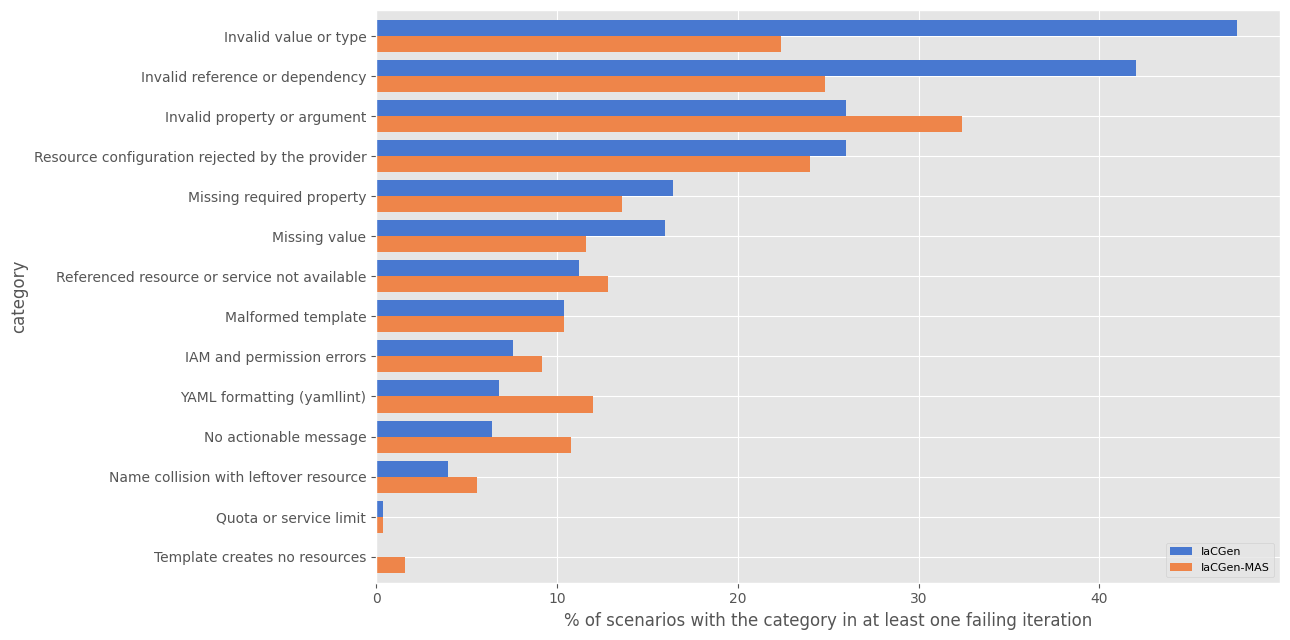

In [7]:
fig, ax = plt.subplots(figsize=(13, 6.5))
top = [c for c in tab.index if ec.STAGE_OF.get(c, "Deployment") != "Security"][:14]
(blocked.loc[top, SYS] / N[SYS] * 100).plot.barh(ax=ax, width=0.8)
ax.set_xlabel("% of scenarios with the category in at least one failing iteration"); ax.invert_yaxis(); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Iteration 1 vs repair iterations

In [8]:
def phase(sel):
    o = occ[sel]
    return o.drop_duplicates(["exp", "run_id", "category"]).groupby(["category", "exp"]).size().unstack("exp").reindex(columns=SYS).fillna(0).astype(int)
a1, a2 = phase(occ.iteration == 1), phase(occ.iteration >= 2)
idx = [c for c in tab.index if ec.STAGE_OF.get(c, "Deployment") != "Security"]
pd.concat({"iteration 1 (% scenarios)": (a1 / N[SYS] * 100).round(1).reindex(idx).fillna(0), "iterations 2+ (% scenarios)": (a2 / N[SYS] * 100).round(1).reindex(idx).fillna(0)}, axis=1)

iteration 1 (% scenarios)            iterations 2+ (% scenarios)           
exp                                                                IaCGen IaCGen-MAS                      IaCGen IaCGen-MAS
category                                                                                                                   
Invalid value or type                                                35.2       15.6                        29.6        8.4
Invalid reference or dependency                                      25.2       16.8                        26.8       11.2
Invalid property or argument                                         21.6       25.2                        11.6        9.6
Resource configuration rejected by the provider                       4.4        6.4                        24.4       20.4
Missing required property                                            10.8        9.6                         9.6        4.4
Missing value                                                         3.2        2.4                        14.0        9.2
Referenced resource or service not available                          3.2        1.2                         8.4       11.6
Malformed template                                                    5.2        8.8                         6.4        2.4
IAM and permission errors                                             2.0        2.0                         6.4        8.4
YAML formatting (yamllint)                                            4.4       11.2                         4.8        3.6
No actionable message                                                 0.8        1.2                         6.4       10.4
Name collision with leftover resource                                 0.8        0.4                         3.6        5.6
Quota or service limit                                                0.4        0.0                         0.4        0.4
Template creates no resources                                         0.0        0.8                         0.0        1.2
Transient provider failure or account state                           0.0        0.0                         0.0        0.4

In [9]:
f1 = iters[iters.iteration == 1].groupby("exp").agg(scenarios=("run_id", "nunique"), failing_first=("failing", "sum"))
f1["first_attempt_pass_%"] = (100 * (1 - f1.failing_first / f1.scenarios)).round(1)
f1.join(iters[iters.iteration >= 2].groupby("exp").run_id.nunique().rename("scenarios needing repair")).join(iters[iters.iteration >= 2].groupby("exp").size().rename("repair iterations")).loc[SYS]

,scenarios,failing_first,first_attempt_pass_%,scenarios needing repair,repair iterations
exp,,,,,
IaCGen,250,192,23.2,191,950
IaCGen-MAS,250,202,19.2,202,711


## Repair efficacy per category

In [10]:
CLS_RAN = {"syntax": "syntax_ran", "schema": "schema_ran", "security": "security_ran", "deploy": "deploy_ran"}
CLS_OF = {"Syntax": "syntax", "Schema": "schema", "Security": "security", "Deployment": "deploy", "Environment": "deploy"}
FAILED_RUNS = set(runs.loc[~runs.passed, "run_id"].astype(str))
_ep = []
for (e, rid), g in iters.groupby(["exp", "run_id"], sort=False):
    g = g.sort_values("iteration"); its = g.iteration.tolist(); ok = g.validation_passed.astype(bool).tolist()
    ran = g[list(CLS_RAN.values())].to_dict("records")
    cats = [it_cats.get((e, rid, i), set()) for i in its]
    for c in set().union(*cats):
        f = next(k for k, s in enumerate(cats) if c in s)
        cl = CLS_OF.get(ec.STAGE_OF.get(c, "Deployment"), "deploy")
        res = next((k for k in range(f + 1, len(its)) if c not in cats[k] and (ok[k] or ran[k][CLS_RAN[cl]])), None)
        _ep.append((e, rid, c, res is not None, (its[res] - its[f]) if res is not None else np.nan, str(rid) in FAILED_RUNS and c in cats[-1]))
ep = pd.DataFrame(_ep, columns=["exp", "run_id", "category", "resolved", "latency", "unresolved"])
ep["stage"] = ep.category.map(lambda c: ec.STAGE_OF.get(c, "Deployment"))
ep = ep[ep.stage != "Security"]
rows = []
for c in ep.category.value_counts().index:
    x = ep[ep.category == c]; row = {"stage": x.stage.iloc[0], "category": c}
    for k in SYS:
        xe = x[x.exp == k]
        row[f"{k[:12]} episodes"] = len(xe)
        row[f"{k[:12]} 1-turn %"] = round(100 * (xe.latency == 1).mean(), 1) if len(xe) else np.nan
        row[f"{k[:12]} mean turns"] = round(xe.latency.mean(), 2) if len(xe) else np.nan
        row[f"{k[:12]} unresolved"] = int(xe.unresolved.sum())
    rows.append(row)
eff = pd.DataFrame(rows).set_index("category")
eff[eff.filter(like="episodes").sum(axis=1) >= 10]

,stage,IaCGen episodes,IaCGen 1-turn %,IaCGen mean turns,IaCGen unresolved,IaCGen-MAS episodes,IaCGen-MAS 1-turn %,IaCGen-MAS mean turns,IaCGen-MAS unresolved
category,,,,,,,,,
Invalid value or type,Schema,118,69.5,1.41,5,56,92.9,1.07,0
Invalid reference or dependency,Schema,104,82.7,1.34,3,62,88.7,1.18,0
Invalid property or argument,Schema,65,73.8,1.52,6,81,91.4,1.09,0
Resource configuration rejected by the provider,Deployment,65,46.2,2.39,3,60,56.7,2.13,0
Missing required property,Schema,41,65.9,1.78,8,34,97.1,1.03,0
Missing value,Deployment,40,62.5,1.82,1,29,89.7,1.14,0
Referenced resource or service not available,Deployment,27,40.7,2.04,0,32,68.8,1.56,0
Malformed template,Syntax,24,79.2,1.38,0,26,88.5,1.19,0
YAML formatting (yamllint),Syntax,17,52.9,1.73,1,30,76.7,1.37,0


In [11]:
rows = []
for c in ep.category.value_counts().index:
    a = ep[(ep.category == c) & (ep.exp == IG)]
    for ref in (CT,):
        b = ep[(ep.category == c) & (ep.exp == ref)]
        if len(a) < 8 or len(b) < 8: continue
        t1 = [[(a.latency == 1).sum(), (a.latency != 1).sum()], [(b.latency == 1).sum(), (b.latency != 1).sum()]]
        rows.append({"category": c, "vs": ref, "IaCGen episodes": len(a), "ref episodes": len(b), "IaCGen 1-turn %": round(100 * (a.latency == 1).mean(), 1),
                     "ref 1-turn %": round(100 * (b.latency == 1).mean(), 1), "p": round(stats.fisher_exact(t1)[1], 4),
                     "IaCGen unresolved %": round(100 * a.unresolved.mean(), 1), "ref unresolved %": round(100 * b.unresolved.mean(), 1)})
pd.DataFrame(rows).set_index(["category", "vs"])

,,IaCGen episodes,ref episodes,IaCGen 1-turn %,ref 1-turn %,p,IaCGen unresolved %,ref unresolved %
category,vs,,,,,,,
Invalid value or type,IaCGen-MAS,118,56,69.5,92.9,0.0004,4.2,0.0
Invalid reference or dependency,IaCGen-MAS,104,62,82.7,88.7,0.3722,2.9,0.0
Invalid property or argument,IaCGen-MAS,65,81,73.8,91.4,0.0064,9.2,0.0
Resource configuration rejected by the provider,IaCGen-MAS,65,60,46.2,56.7,0.2841,4.6,0.0
Missing required property,IaCGen-MAS,41,34,65.9,97.1,0.0009,19.5,0.0
Missing value,IaCGen-MAS,40,29,62.5,89.7,0.0132,2.5,0.0
Referenced resource or service not available,IaCGen-MAS,27,32,40.7,68.8,0.0384,0.0,0.0
Malformed template,IaCGen-MAS,24,26,79.2,88.5,0.4561,0.0,0.0
YAML formatting (yamllint),IaCGen-MAS,17,30,52.9,76.7,0.1144,5.9,0.0


In [12]:
bs = ep.groupby(["stage", "exp"]).agg(episodes=("resolved", "size"), resolved_pct=("resolved", lambda s: round(100 * s.mean(), 1)), one_turn_pct=("latency", lambda s: round(100 * (s == 1).mean(), 1)),
                                      mean_turns=("latency", lambda s: round(s.mean(), 2)), unresolved=("unresolved", "sum")).unstack("exp")
bs.reindex(columns=pd.MultiIndex.from_product([bs.columns.levels[0], SYS]))

episodes            resolved_pct            one_turn_pct            mean_turns            unresolved           
              IaCGen IaCGen-MAS       IaCGen IaCGen-MAS       IaCGen IaCGen-MAS     IaCGen IaCGen-MAS     IaCGen IaCGen-MAS
stage                                                                                                                      
Deployment       164        175         93.3       99.4         48.8       64.0       2.25       1.98         15          2
Environment       11         16         72.7      100.0         36.4       81.2       3.50       1.56          2          0
Schema           328        233         96.6      100.0         74.1       91.8       1.45       1.10         22          0
Syntax            41         56         95.1      100.0         68.3       82.1       1.51       1.29          1          0

## Recurrence of the same category in the next iteration

In [13]:
_one = occ.drop_duplicates(["exp", "run_id", "iteration", "category"])
sets = _one.groupby(["exp", "run_id", "iteration"]).category.agg(set).to_dict()
rec = []
for (e, rid), g in iters.groupby(["exp", "run_id"], sort=False):
    its = g.sort_values("iteration").iteration.tolist()
    for a, b in zip(its[:-1], its[1:]):
        for cat in sets.get((e, rid, a), set()):
            rec.append((e, cat, cat in sets.get((e, rid, b), set())))
rec = pd.DataFrame(rec, columns=["exp", "category", "recurs"])
rec["stage"] = rec.category.map(lambda c: ec.STAGE_OF.get(c, "Deployment"))
rec = rec[rec.stage != "Security"]
rs = rec.groupby(["stage", "exp"]).recurs.agg(["size", lambda s: round(100 * s.mean(), 1)]).unstack("exp")
rs

size            <lambda_0>           
exp         IaCGen IaCGen-MAS     IaCGen IaCGen-MAS
stage                                              
Deployment     392        367       40.6       43.3
Environment     26         25       34.6       32.0
Schema         703        274       39.7       10.6
Syntax          71         72       29.6       22.2

In [14]:
rows = []
for c in rec.category.value_counts().index:
    a = rec[(rec.category == c) & (rec.exp == IG)]
    for ref in (CT,):
        b = rec[(rec.category == c) & (rec.exp == ref)]
        if len(a) < 10 or len(b) < 10: continue
        rows.append({"category": c, "vs": ref, "IaCGen transitions": len(a), "ref transitions": len(b), "IaCGen recurs %": round(100 * a.recurs.mean(), 1),
                     "ref recurs %": round(100 * b.recurs.mean(), 1), "p": round(stats.fisher_exact([[a.recurs.sum(), (~a.recurs).sum()], [b.recurs.sum(), (~b.recurs).sum()]])[1], 4)})
pd.DataFrame(rows).set_index(["category", "vs"])

,,IaCGen transitions,ref transitions,IaCGen recurs %,ref recurs %,p
category,vs,,,,,
Invalid value or type,IaCGen-MAS,235,64,34.0,7.8,0.0000
Resource configuration rejected by the provider,IaCGen-MAS,144,142,38.9,46.5,0.2319
Invalid reference or dependency,IaCGen-MAS,197,87,23.9,18.4,0.3543
Invalid property or argument,IaCGen-MAS,137,88,43.1,8.0,0.0000
Missing required property,IaCGen-MAS,134,35,69.4,2.9,0.0000
No actionable message,IaCGen-MAS,73,85,53.4,57.6,0.6321
Missing value,IaCGen-MAS,86,29,39.5,0.0,0.0000
IAM and permission errors,IaCGen-MAS,46,56,45.7,53.6,0.5508
Referenced resource or service not available,IaCGen-MAS,43,50,20.9,28.0,0.4775


## Excess failing iterations per scenario

In [15]:
cnt = iters[iters.functional].groupby(["exp", "row_number"]).size().unstack("exp").reindex(columns=SYS).fillna(0)
cnt = cnt.reindex(ds.row_number).fillna(0)
cnt["excess_vs_control"] = cnt[IG] - cnt[CT]
print("functional failing iterations - IaCGen", int(cnt[IG].sum()), "| IaCGen-MAS", int(cnt[CT].sum()))
print("scenarios where IaCGen needs more than the control:", int((cnt.excess_vs_control > 0).sum()), "| fewer:", int((cnt.excess_vs_control < 0).sum()),
      "| Wilcoxon p:", stats.wilcoxon(cnt[IG], cnt[CT]).pvalue)
heavy = cnt[cnt.excess_vs_control >= 6].sort_values("excess_vs_control", ascending=False).join(ds.set_index("row_number")[["difficulty"]])
heavy

functional failing iterations - IaCGen 969 | IaCGen-MAS 617
scenarios where IaCGen needs more than the control: 116 | fewer: 68 | Wilcoxon p: 6.707802077678793e-06


,IaCGen,IaCGen-MAS,excess_vs_control,difficulty
row_number,,,,
26,15.0,0.0,15.0,1
8,15.0,1.0,14.0,1
87,15.0,1.0,14.0,3
242,15.0,1.0,14.0,2
125,15.0,1.0,14.0,4
121,15.0,1.0,14.0,4
17,15.0,1.0,14.0,1
175,15.0,2.0,13.0,5
72,15.0,2.0,13.0,3


In [16]:
h = occ[occ.row_number.isin(heavy.index) & (occ.cat_stage != "Security")].drop_duplicates(["exp", "run_id", "iteration", "category"])
h.groupby(["category", "exp"]).size().unstack("exp").reindex(columns=SYS).fillna(0).astype(int).sort_values(IG, ascending=False).head(12)

exp,IaCGen,IaCGen-MAS
category,,
Missing required property,94,8
Invalid value or type,88,10
Invalid reference or dependency,73,13
No actionable message,57,14
Resource configuration rejected by the provider,57,22
Invalid property or argument,49,15
Missing value,49,5
Malformed template,25,5
IAM and permission errors,24,9


## IaCGen failures

In [17]:
pv = runs.pivot(index="row_number", columns="exp", values="passed")
pi = runs.pivot(index="row_number", columns="exp", values="iterations_used")
fails = pv[~pv[IG]].index.tolist()
last = iters.sort_values("iteration").groupby(["exp", "row_number"]).tail(1).set_index(["exp", "row_number"]).cats
inv = runs[runs.exp == IG].set_index("row_number").invalid
dif = ds.set_index("row_number").difficulty
fx = pd.DataFrame([{"row": rn, "difficulty": int(dif[rn]), "invalid": bool(inv[rn]), "CT passed": bool(pv.loc[rn, CT]), "CT iters": pi.loc[rn, CT],
                    "IaCGen last-iteration categories": "; ".join(sorted(last.get((IG, rn), set())))[:130]} for rn in fails]).set_index("row")
fx

,difficulty,invalid,CT passed,CT iters,IaCGen last-iteration categories
row,,,,,
2,1,False,False,15.0,No actionable message
6,1,True,False,15.0,No actionable message
8,1,False,True,2.0,Invalid value or type
17,1,False,True,2.0,Missing required property
20,1,False,True,8.0,
26,1,False,True,1.0,IAM and permission errors
37,2,False,True,7.0,No actionable message
58,2,True,True,8.0,Name collision with leftover resource
72,3,False,True,4.0,Invalid property or argument; Missing required property


In [18]:
print("IaCGen failures:", len(fx), "| IaCGen-MAS passed:", int(fx["CT passed"].sum()))
pd.Series([c for s in fx["IaCGen last-iteration categories"] for c in s.split("; ") if c]).value_counts().rename("failing scenarios with the category in the last iteration").to_frame()

IaCGen failures: 31 | IaCGen-MAS passed: 29


,failing scenarios with the category in the last iteration
Missing required property,8
No actionable message,7
Invalid property or argument,6
Invalid value or type,5
IAM and permission errors,4
Resource configuration rejected by the provider,3
Invalid reference or dependency,3
Name collision with leftover resource,2
YAML formatting (yamllint),1
Missing value,1


In [19]:
st = fx["IaCGen last-iteration categories"].map(lambda s: sorted({ec.STAGE_OF.get(c, "Deployment") for c in s.split("; ") if c}))
pd.Series([x for l in st for x in l]).value_counts().rename("failing scenarios by stage of the last-iteration errors").to_frame()

,failing scenarios by stage of the last-iteration errors
Deployment,15
Schema,12
Environment,2
Syntax,1


## Security findings left in the final templates (post-hoc Trivy)

In [20]:
def final_findings(k, e):
    t = pd.read_csv(RES / f"Trivy_{e}.csv"); r = pd.read_csv(FINAL / e / "results_final.csv", usecols=["run_id", "row_number"], low_memory=False)
    t = t.merge(r, on="run_id", how="left")
    out = []
    for x in t.itertuples():
        ids = [i for i in str(x.failed_check_ids).split("|") if i and i != "nan"] if isinstance(x.failed_check_ids, str) else []
        cats = set()
        for i in ids:
            try: cats.add(ec.security_category(i, SEC_CHECKS)[0])
            except Exception: cats.add(ec.UNMAPPED)
        out.append(cats)
    t["cats"] = out; t["exp"] = k
    return t
tf = pd.concat([final_findings(IG, "CFN_RealAWS_IaCGen_DSV4Flash"), final_findings(CT, MAS[CT])], ignore_index=True)
sc = [c for s, c in ec.CATEGORIES if s == "Security"]
pd.DataFrame({k: {**{c: round(100 * tf[tf.exp == k].cats.map(lambda s, c=c: c in s).mean(), 1) for c in sc},
                  "any finding": round(100 * tf[tf.exp == k].cats.map(len).gt(0).mean(), 1)} for k in SYS}).T

,Encryption missing or weak,Network exposure,Access control and public access,Logging and monitoring,any finding
IaCGen,8.8,1.2,2.8,10.0,58.8
IaCGen-MAS,10.4,1.6,2.0,11.2,59.2


## Numbers for the thesis

In [21]:
one = occ.drop_duplicates(["exp", "run_id", "category"]).groupby(["category", "exp"]).size().unstack("exp").reindex(columns=SYS).fillna(0).astype(int)
rows = []
for c in one.index:
    st = ec.STAGE_OF.get(c, "Deployment")
    if st == "Security":
        continue
    r = {"stage": st, "category": c}
    for k in SYS:
        e = ep[(ep.category == c) & (ep.exp == k)]
        r[f"{k} blocked"] = int(one.loc[c, k])
        r[f"{k} unresolved"] = int(e.unresolved.sum())
        r[f"{k} first attempt"] = int(a1.loc[c, k]) if c in a1.index else 0
        r[f"{k} one turn %"] = round(100 * (e.latency == 1).mean(), 1) if len(e) else np.nan
        r[f"{k} episodes"] = len(e)
        r[f"{k} one turn int"] = int(np.floor(100 * (e.latency == 1).sum() / len(e) + 0.5)) if len(e) else np.nan
    rows.append(r)
order = {s: i for i, s in enumerate(["Syntax", "Schema", "Deployment", "Environment"])}
cat_tab = pd.DataFrame(rows).sort_values(["stage", f"{IG} blocked"], key=lambda s: s.map(order) if s.name == "stage" else -s).set_index(["stage", "category"])
fi = iters[iters.failing]
rec_s = rec.groupby(["stage", "exp"]).recurs.mean().unstack("exp")
err_summary = pd.DataFrame({k: {"failing iterations": len(fi[fi.exp == k]), "failing iterations per scenario": round(len(fi[fi.exp == k]) / N[k], 2),
                                "first attempt pass %": f1.loc[k, "first_attempt_pass_%"],
                                "schema share of failing iterations %": round(100 * fi[fi.exp == k].cats.map(lambda c: any(ec.STAGE_OF.get(x, "Deployment") == "Schema" for x in c)).mean(), 1),
                                "schema recurrence %": round(100 * rec_s.loc["Schema", k], 1), "deployment recurrence %": round(100 * rec_s.loc["Deployment", k], 1),
                                "unresolved schema episodes": int(ep[(ep.exp == k) & (ep.stage == "Schema")].unresolved.sum())} for k in SYS}).T
cat_tab.to_csv(RES / "IaCGen_vs_MAS_DSV4F_categories.csv")
err_summary.to_csv(RES / "IaCGen_vs_MAS_DSV4F_error_summary.csv")
display(err_summary)
cat_tab


,failing iterations,failing iterations per scenario,first attempt pass %,schema share of failing iterations %,schema recurrence %,deployment recurrence %,unresolved schema episodes
IaCGen,970.0,3.88,23.2,49.1,39.7,40.6,22.0
IaCGen-MAS,714.0,2.86,19.2,29.0,10.6,43.3,0.0


IaCGen blocked  IaCGen unresolved  IaCGen first attempt  IaCGen one turn %  IaCGen episodes  IaCGen one turn int  IaCGen-MAS blocked  IaCGen-MAS unresolved  \
stage       category                                                                                                                                                                                                       
Syntax      Malformed template                                           26                  0                    13               79.2               24                 79.0                  26                      0   
            YAML formatting (yamllint)                                   17                  1                    11               52.9               17                 53.0                  30                      0   
Schema      Invalid value or type                                       119                  5                    88               69.5              118                 69.0                  56                      0   
            Invalid reference or dependency                             105                  3                    63               82.7              104                 83.0                  62                      0   
            Invalid property or argument                                 65                  6                    54               73.8               65                 74.0                  81                      0   
            Missing required property                                    41                  8                    27               65.9               41                 66.0                  34                      0   
Deployment  Resource configuration rejected by the provider              65                  3                    11               46.2               65                 46.0                  60                      0   
            Missing value                                                40                  1                     8               62.5               40                 63.0                  29                      0   
            Referenced resource or service not available                 28                  0                     8               40.7               27                 41.0                  32                      0   
            IAM and permission errors                                    19                  4                     5               61.1               18                 61.0                  23                      0   
            No actionable message                                        16                  7                     2               21.4               14                 21.0                  27                      2   
            Template creates no resources                                 0                  0                     0                NaN                0                  NaN                   4                      0   
Environment Name collision with leftover resource                        10                  2                     2               40.0               10                 40.0                  14                      0   
            Quota or service limit                                        1                  0                     1                0.0                1                  0.0                   1                      0   
            Transient provider failure or account state                   0                  0                     0                NaN                0                  NaN                   1                      0   

                                                             IaCGen-MAS first attempt  IaCGen-MAS one turn %  IaCGen-MAS episodes  IaCGen-MAS one turn int  
stage       category                                                                                                                                        
Syntax